<a href="https://colab.research.google.com/github/adilbashir017-ux/Data-Mining-and-Machine-Learning-/blob/main/Labs/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Braude College of Engineering - Data Mining & Machine Learning (61761)
# Lab 2: Text Preprocessing, K-Nearest Neighbors (KNN) & Model Evaluation

מגישים:


עאדל בשיר   --- קבוצת יום שלישי


נאדין חג    -- קבוצת יום ראשון

### 1. Imports

In [57]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [58]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Dataset Loading (Text Sentiment / Spam Sample)

In [59]:
# Sample text corpus representing customer feedback
sample_data = {
    "text": [
        "Great service, fast delivery and very friendly staff",
        "Terrible experience, arrived damaged and very late",
        "Awesome quality, exceeded all my expectations",
        "Poor customer support, refused to give a refund",
        "Loved the product, works like a charm every day",
        "Waste of money, completely broken on arrival",
        "Highly recommended, will definitely buy again soon",
        "Worst purchase ever, do not recommend to anyone",
        "Super happy with the performance and compact design",
        "Horrible smell, poor material and extremely cheap quality",
        "Excellent craftsmanship and fast responsive support",
        "Very disappointed, stop working after just two days",
        "Best deal online, reasonable price and good shipping",
        "Defective unit, customer representative was rude",
        "Impressed with the battery life and sharp screen",
        "Never buying again, totally unsatisfied with order",
        "Five stars, reliable device and beautiful color",
        "Bad quality, broke during first usage unfortunately",
        "Top notch customer care, resolved my issue quickly",
        "Do not buy, low grade plastic and missing accessories",
        "Outstanding product, very easy setup and use",
        "Awful packaging, item crushed inside the box",
        "Wonderful experience from ordering to unboxing",
        "Failed immediately, return process is a nightmare"
    ],
    "label": [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
}
df = pd.DataFrame(sample_data)
display(df.head())
print("Class distribution:\n", df["label"].value_counts())

,text,label
0,"Great service, fast delivery and very friendly...",1
1,"Terrible experience, arrived damaged and very ...",0
2,"Awesome quality, exceeded all my expectations",1
3,"Poor customer support, refused to give a refund",0
4,"Loved the product, works like a charm every day",1


Class distribution:
 label
1    12
0    12
Name: count, dtype: int64


### 3. Bag-of-Words Representation & Stratified Split

In [60]:
# Bag-of-Words with standard English stop words removed
vectorizer = CountVectorizer(stop_words="english")
X_bow = vectorizer.fit_transform(df["text"])
y = df["label"]

print(f"Vocabulary size (with stop words removed): {len(vectorizer.vocabulary_)}")

# Stratified 75% Train / 25% Test split
X_train, X_test, y_train, y_test = train_test_split(
    X_bow, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Vocabulary size (with stop words removed): 114
Train shape: (18, 114), Test shape: (6, 114)


### 4. Baseline KNN Model & Accuracy Evaluation (Demo)

In [61]:
knn_demo = KNeighborsClassifier(n_neighbors=5)
knn_demo.fit(X_train, y_train)

y_pred_demo = knn_demo.predict(X_test)
acc_demo = accuracy_score(y_test, y_pred_demo)
print(f"Baseline KNN (K=5) Test Accuracy: {acc_demo:.4f}")

Baseline KNN (K=5) Test Accuracy: 0.5000


### 5. ROC Curve Demo

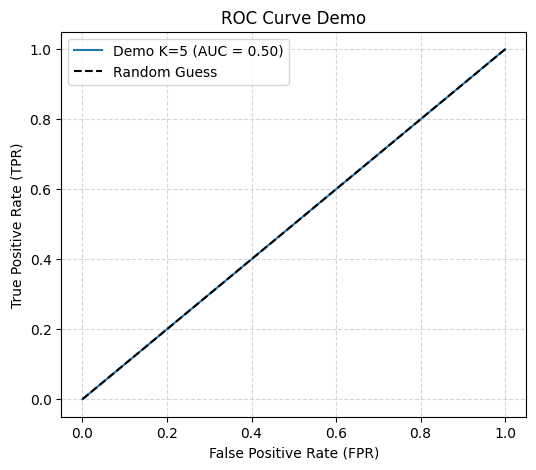

In [62]:
y_probs_demo = knn_demo.predict_proba(X_test)[:, 1]
fpr_demo, tpr_demo, _ = roc_curve(y_test, y_probs_demo)
auc_demo = roc_auc_score(y_test, y_probs_demo)

plt.figure(figsize=(6, 5))
plt.plot(fpr_demo, tpr_demo, label=f"Demo K=5 (AUC = {auc_demo:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve Demo")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 6. Hyperparameter Loop (K values) & Cross-Validation Demo

In [63]:
# Demonstration of checking multiple K values
k_candidates = [1, 3, 5]
for k in k_candidates:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))
    print(f"K={k:2d} -> Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")

K= 1 -> Train Accuracy: 1.0000 | Test Accuracy: 0.5000
K= 3 -> Train Accuracy: 0.7778 | Test Accuracy: 0.3333
K= 5 -> Train Accuracy: 0.5556 | Test Accuracy: 0.5000


In [64]:
# Demonstration of 5-Fold Cross-Validation
cv_scores = cross_val_score(knn_demo, X_train, y_train, cv=5, scoring="accuracy")
print(f"\n5-Fold CV Accuracy for K=5: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


5-Fold CV Accuracy for K=5: 0.5000 (+/- 0.1054)


## PART B: Independent Student Tasks

### Task 1: Stop Words Impact on Vocabulary Size
1. Instantiate a new `CountVectorizer` with `stop_words=None` and fit it on `df['text']`.
2. Print the vocabulary size with and without stop words.
3. State the difference in feature dimensions.

### Task 1 - Vocabulary Size Comparison

This task compares the vocabulary size with and without stop word removal.

A new CountVectorizer is created without removing stop words, and the vocabulary sizes are compared to calculate the exact difference.

In [65]:
# TODO 1.1: Build vectorizer with stop_words=None and check vocabulary size
# Step 1: Create a vectorizer without stop word removal
vectorizer_no_stop = CountVectorizer(stop_words=None)
vectorizer_no_stop.fit(df["text"])

# Step 2: Calculate vocabulary sizes
size_with_stop = len(vectorizer_no_stop.vocabulary_)
size_without_stop = len(vectorizer.vocabulary_)

# Step 3: Calculate the difference
difference = size_with_stop - size_without_stop

# Step 4: Display the results
print("Vocabulary size with stop words:", size_with_stop)
print("Vocabulary size without stop words:", size_without_stop)
print("Difference:", difference)


Vocabulary size with stop words: 141
Vocabulary size without stop words: 114
Difference: 27


### Task 1 - Conclusion

The vocabulary contains 141 features before removing stop words and 114 features after removing them.

The exact difference is 27 features.

Removing stop words reduces the vocabulary size by eliminating common English words, which helps simplify the text representation.

### Task 2: Extended Evaluation Metrics for Baseline Model
1. Generate predictions on `X_test` using the baseline model `knn_demo` (K=5).
2. Display the Confusion Matrix.
3. Compute and print Precision, Recall, and F1-score formatted to 4 decimal places.

### Task 2 - Model Evaluation

This task evaluates the baseline KNN model (K=5) using the test dataset.

The Confusion Matrix is calculated to examine correct and incorrect predictions.

Precision, Recall, and F1-Score are computed to evaluate the classification performance.

In [66]:
# TODO 2.1: Confusion matrix and detailed classification metrics (Precision, Recall, F1)
# Step 1: Generate predictions using the baseline KNN model (K=5)
y_pred_task2 = knn_demo.predict(X_test)

# Step 2: Calculate and display the Confusion Matrix
cm = confusion_matrix(y_test, y_pred_task2)

print("Confusion Matrix:")
print(cm)

# Step 3: Calculate evaluation metrics
precision = precision_score(y_test, y_pred_task2, zero_division=0)
recall = recall_score(y_test, y_pred_task2, zero_division=0)
f1 = f1_score(y_test, y_pred_task2, zero_division=0)

# Step 4: Display the results
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")


Confusion Matrix:
[[0 3]
 [0 3]]
Precision: 0.5000
Recall: 1.0000
F1-Score: 0.6667


### Task 2 - Conclusion

The Confusion Matrix shows that the model correctly classified 3 positive samples but incorrectly classified all 3 negative samples as positive.

The evaluation results are:
- Precision: 0.5000
- Recall: 1.0000
- F1-Score: 0.6667

Although the model achieved perfect Recall, it predicted all test samples as positive, resulting in only 50% accuracy.

Therefore, the baseline KNN model (K=5) does not distinguish well between positive and negative samples.

### Task 3: Hyperparameter Tuning & Overfitting Inspection
1. Iterate over K values: `[1, 3, 5, 9, 17, 33]` (handle cases where K exceeds training samples gracefully).
2. Print a table of Train Accuracy vs. Test Accuracy for each K.
3. Identify which K yields the highest Test Accuracy, and explain the behavior at K=1.

### Task 3 - Hyperparameter Tuning

This task evaluates the KNN model using different K values: 1, 3, 5, 9, 17, and 33.

For each valid K, the model is trained and evaluated using both training and testing data.

The results are displayed in a comparison table to identify the K value with the highest test accuracy.

K values exceeding the number of training samples are skipped.

In [67]:
# TODO 3.1: Iterate over K values and display the comparison table

# Step 1: Define K values
k_candidates = [1, 3, 5, 9, 17, 33]
results = []

# Step 2: Train and evaluate KNN for each K
for k in k_candidates:

    if k > X_train.shape[0]:
        print(f"K={k} skipped: exceeds training samples")
        continue

    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))

    results.append([k, train_acc, test_acc])

# Step 3: Display the comparison table
results_df = pd.DataFrame(
    results,
    columns=["K", "Train Accuracy", "Test Accuracy"]
)

display(results_df)

# Step 4: Identify the best K values
best_test_acc = results_df["Test Accuracy"].max()

best_k_values = results_df.loc[
    results_df["Test Accuracy"] == best_test_acc, "K"
].tolist()

# Step 5: Select K=5 among the tied best values
# Select the smallest tied best K greater than 1
best_k = min(
    (k for k in best_k_values if k > 1),
    default=min(best_k_values)
)

# Step 6: Display the final results
print(f"Best K value(s): {best_k_values}")
print(f"Highest Test Accuracy: {best_test_acc:.4f}")
print(f"Selected K for the next tasks: {best_k}")


K=33 skipped: exceeds training samples


,K,Train Accuracy,Test Accuracy
0,1,1.000000,0.500000
1,3,0.777778,0.333333
2,5,0.555556,0.500000
3,9,0.666667,0.500000
4,17,0.555556,0.500000


Best K value(s): [1, 5, 9, 17]
Highest Test Accuracy: 0.5000
Selected K for the next tasks: 5


**Observation for Task 3:**

**Best K value:**
K=1, 5, 9, and 17 achieved the highest Test Accuracy of 0.5000. K=5 was selected for the next tasks.

**Behavior observed at K=1 (Overfitting explanation):**
At K=1, the model achieved 100% Training Accuracy but only 50% Test Accuracy. This indicates overfitting, as the model fits the training data perfectly but performs poorly on unseen data.

### Task 4: Stratified Cross-Validation on Optimal K
1. Using your optimal K from Task 3, configure a KNN classifier.
2. Execute a 5-Fold Cross-Validation on `X_train` and `y_train` using `scoring='f1'`.
3. Print the individual fold scores, the mean F1 score, and the standard deviation.

### Task 4 - Stratified Cross-Validation

This task evaluates the selected KNN model (K=5) using 5-Fold Stratified Cross-Validation.

The model is evaluated using the F1-Score for each fold.

The mean F1-Score and standard deviation are calculated to assess the model's performance and stability across different training splits.

In [68]:
# TODO 4.1: Perform 5-fold CV with F1 scoring on the optimal K model
# Step 1: Create KNN model using the selected K
knn_optimal = KNeighborsClassifier(n_neighbors=best_k)

# Step 2: Perform 5-Fold Stratified Cross-Validation
cv_scores = cross_val_score(
    knn_optimal, X_train, y_train, cv=5, scoring="f1"
)

# Step 3: Display the 5-fold F1 scores
print("5-Fold F1 Scores:", cv_scores)

# Step 4: Calculate and display the mean and standard deviation
print(f"Mean F1 Score: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")


5-Fold F1 Scores: [0.         0.         0.66666667 0.5        0.8       ]
Mean F1 Score: 0.3933
Standard Deviation: 0.3349


### Task 4 - Conclusion

The 5-Fold Stratified Cross-Validation produced the following F1 scores:

[0.0000, 0.0000, 0.6667, 0.5000, 0.8000]

- Mean F1-Score: 0.3933
- Standard Deviation: 0.3349

The relatively low mean F1-Score and high standard deviation indicate that the model's performance varies significantly across different folds.

Therefore, the KNN model (K=5) does not show stable classification performance on this small dataset.

### Task 5: Comparative ROC Curves
1. Compute prediction probabilities (`predict_proba`) for K=1 and your optimal K.
2. Plot both ROC curves on the same chart, including labels with their respective AUC scores.
3. Explain which model is preferable and why.

### Task 5 - Comparative ROC Curves

This task compares the classification performance of KNN models with K=1 and K=5.

Prediction probabilities are calculated for both models using the test dataset.

ROC curves are plotted on the same chart, including a diagonal random-guess reference line.

The AUC scores are calculated to compare the models' ability to distinguish between positive and negative samples.

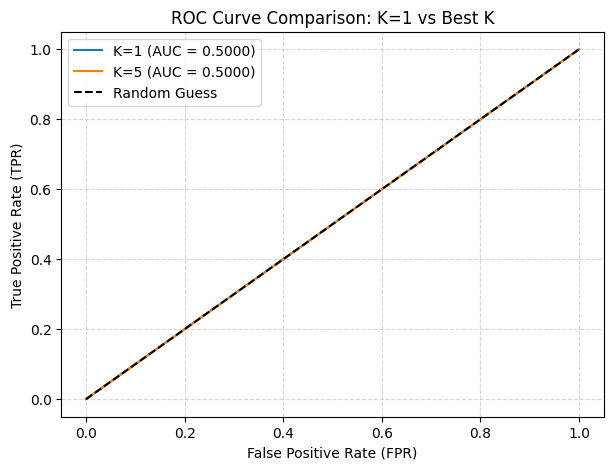

AUC for K=1: 0.5000
AUC for K=5: 0.5000


In [69]:
# TODO 5.1: Plot comparative ROC curves and print AUC values
# Step 1: Create and train KNN models
knn_k1 = KNeighborsClassifier(n_neighbors=1)
knn_k1.fit(X_train, y_train)

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)

# Step 2: Calculate prediction probabilities
y_probs_k1 = knn_k1.predict_proba(X_test)[:, 1]
y_probs_best = knn_best.predict_proba(X_test)[:, 1]

# Step 3: Calculate ROC curves
fpr_k1, tpr_k1, _ = roc_curve(y_test, y_probs_k1)
fpr_best, tpr_best, _ = roc_curve(y_test, y_probs_best)

# Step 4: Calculate AUC scores
auc_k1 = roc_auc_score(y_test, y_probs_k1)
auc_best = roc_auc_score(y_test, y_probs_best)

# Step 5: Plot both ROC curves
plt.figure(figsize=(7, 5))

plt.plot(fpr_k1, tpr_k1, label=f"K=1 (AUC = {auc_k1:.4f})")
plt.plot(fpr_best, tpr_best, label=f"K={best_k} (AUC = {auc_best:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve Comparison: K=1 vs Best K")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Step 6: Display AUC scores
print(f"AUC for K=1: {auc_k1:.4f}")
print(f"AUC for K={best_k}: {auc_best:.4f}")


### Task 5 - Conclusion

Both KNN models achieved an AUC score of 0.5000.

The ROC curves overlap with the random-guess reference line, indicating that neither model effectively distinguishes between positive and negative samples.

Therefore, neither K=1 nor K=5 demonstrates better generalization based on the ROC-AUC results.

A larger dataset would be needed for a more reliable evaluation.